# Figure 6 — ExPert reveals a monocyte-restricted mitochondrial loss-of-function signature in primary mitochondrial disease

Renders panels B–I from the cached tables in `data/` (PMD PBMC scores from `fig6_pmd.py` / `fig6_donor_mag.py` /
`fig6_rna.py` / `fig6_supervised.py`, sorted-cell bulk PCA from `fig6_bulk.py`, the flow-cytometry workbook) plus the
gene-set files linked in `inputs/` (collaborator modules, Reactome 2024). Panels go to `render/`, the source tables
they emit to `render/src/`.

Not rendered here (static artwork, no script draws them):
- **A** — study-design schematic (`fig6a.png`, drawn by hand).
- **G, left** — the sorted-cell culture / stimulation schematic (added at figure assembly; the script draws only the PCA).

In [1]:
import sys
from pathlib import Path
_paper = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts' / 'common').is_dir())
sys.path.insert(0, str(_paper / 'scripts' / 'common'))
import nbtools as nb                      # puts paper/scripts/*/ on sys.path

vs = nb.vizstyle()
DATA, INPUTS, OUT, SRC = nb.folders()     # data/ (cache), inputs/, render/, render/src/

In [2]:
import fig6_pmd_plot as P
import fig6_pmd_panel_plot as PE
import fig6_bulk_plot as PB
import fig6_flow_plot as PF

STYLE = str(nb.STYLE)                       # vizstyle root (paper/style)
OUT_, SRC_ = (str(p.relative_to(Path.cwd())) for p in (OUT, SRC))   # render/, render/src/ as relative paths
P.setup(STYLE)
a = P.build_parser().parse_args([
    '--data-dir', 'data/pmd_mtmt/score', '--out-dir', OUT_, '--src-dir', SRC_, '--vizstyle-root', STYLE,
    '--modules', 'inputs/leigh_modules.tsv', '--reactome-gmt', 'inputs/Enrichr.Reactome_Pathways_2024.gmt',
    '--rna-dir', 'data/rna', '--panel-dir', 'data/pmd_panel',
    '--donor-mag', 'data/pmd_panel/donor_mag_trained.csv.gz', '--pmd-genes', 'data/PMD_gene_list.csv'])
score = DATA / 'pmd_mtmt' / 'score'
cts = [c for c in P.CT if c not in a.c_drop and c != 'NK cells']   # cell-type columns of F

## B — single-cell DE log2FC vs ExPert score, PMD vs reference monocytes

[fig6b_deg_vs_expert] PMD list: 44 genes, 44 in the plot, 12 outside the pathway groups


[fig6b_deg_vs_expert] Spearman |log2FC| vs |ExPert| 0.034, signed -0.039 (n=8615)


  wrote fig6b_deg_vs_expert.svg / .png


[c] module tags: {'none': 115, 'mito-ribosome': 25, 'CI': 15, 'mito import': 8, 'CV': 7, 'CIV': 7, 'mtDNA': 6, 'cap translation': 4, 'CIII': 4, 'mito dynamics': 3, 'Fe–S': 3, 'mTOR': 2, 'CoQ': 1}


[c] wrote render/src/fig6b_top200_expert.csv: 200 genes, PMD 79, groups {'none': 118, 'mito biogenesis': 40, 'OXPHOS': 33, 'mTOR': 6, 'stress': 3}


[fig6b_deg_vs_expert] pathway genes 295: DE down & ExPert loss 54, DE up & loss 197, DE down & gain 12, DE up & gain 32


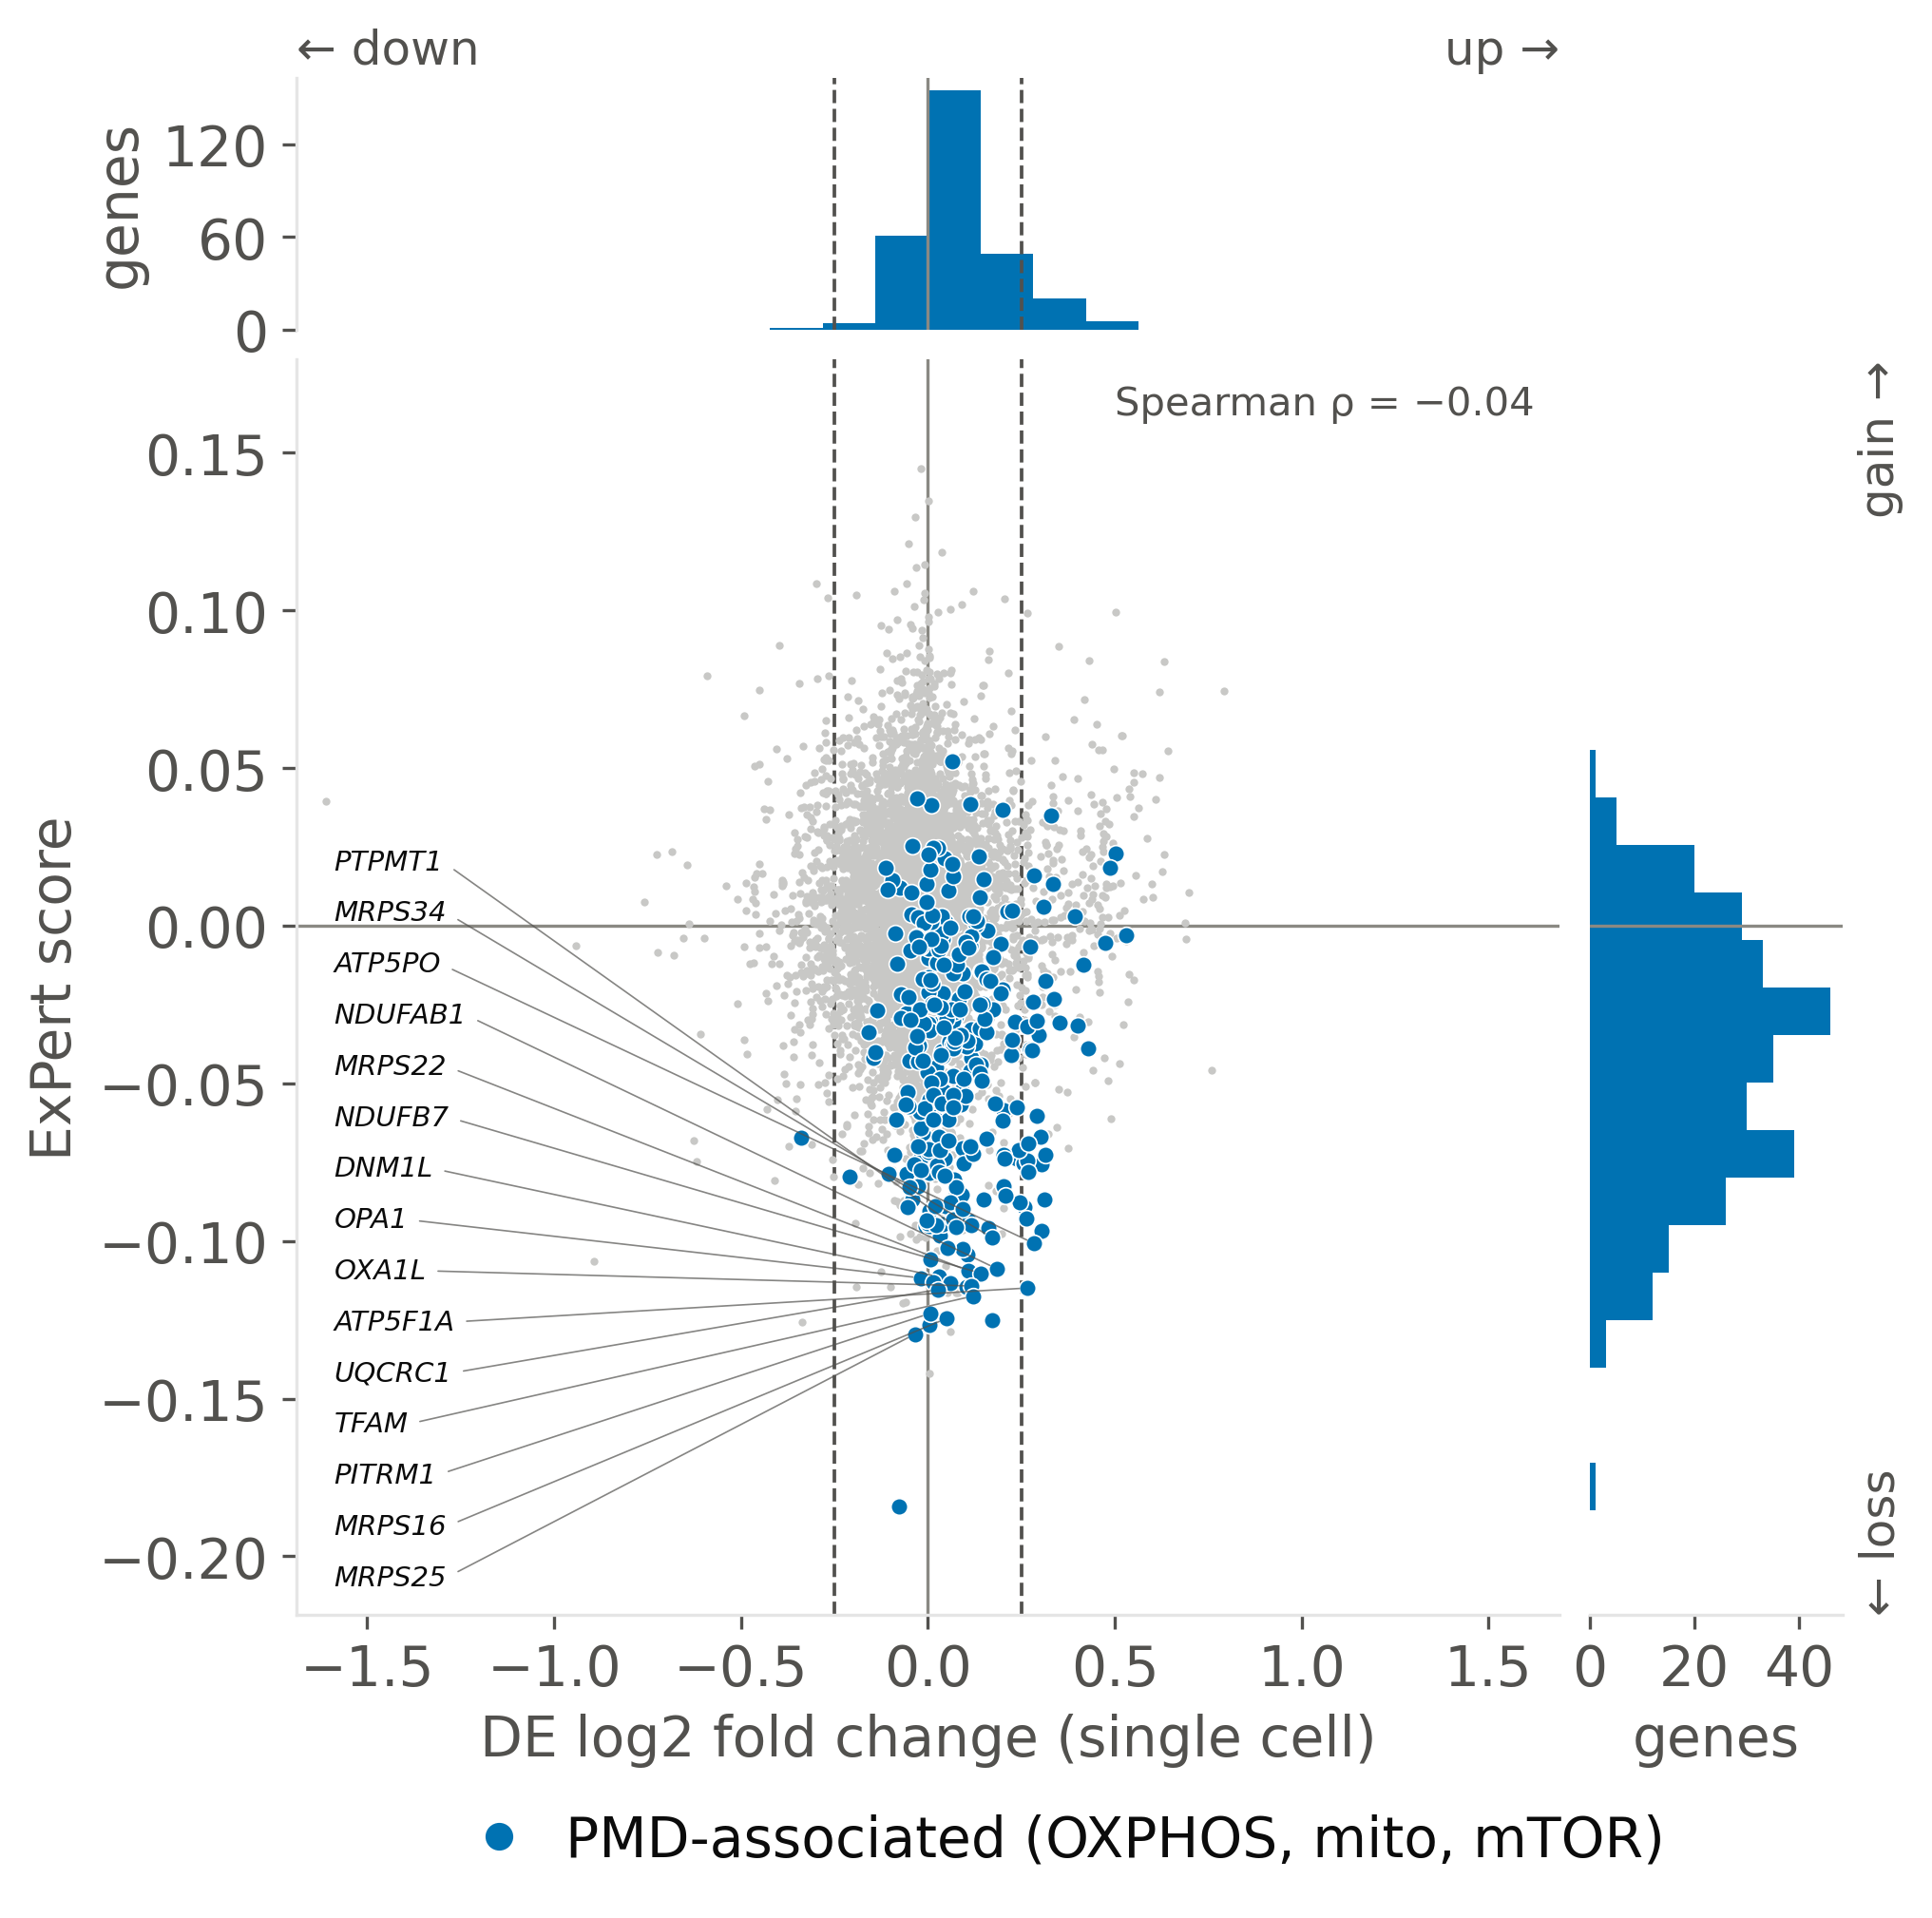

In [3]:
P.panel_c_quadrant(score, OUT, 'Monocytes', a.contrast, a, mode='value', name='fig6b_deg_vs_expert', src_dir=SRC)
nb.show(OUT, 'fig6b_deg_vs_expert')

## C — monocyte UMAP of the ExPert latent, shaded by the uncentred OXPHOS-loss score

  wrote fig6c_umap.svg / .png


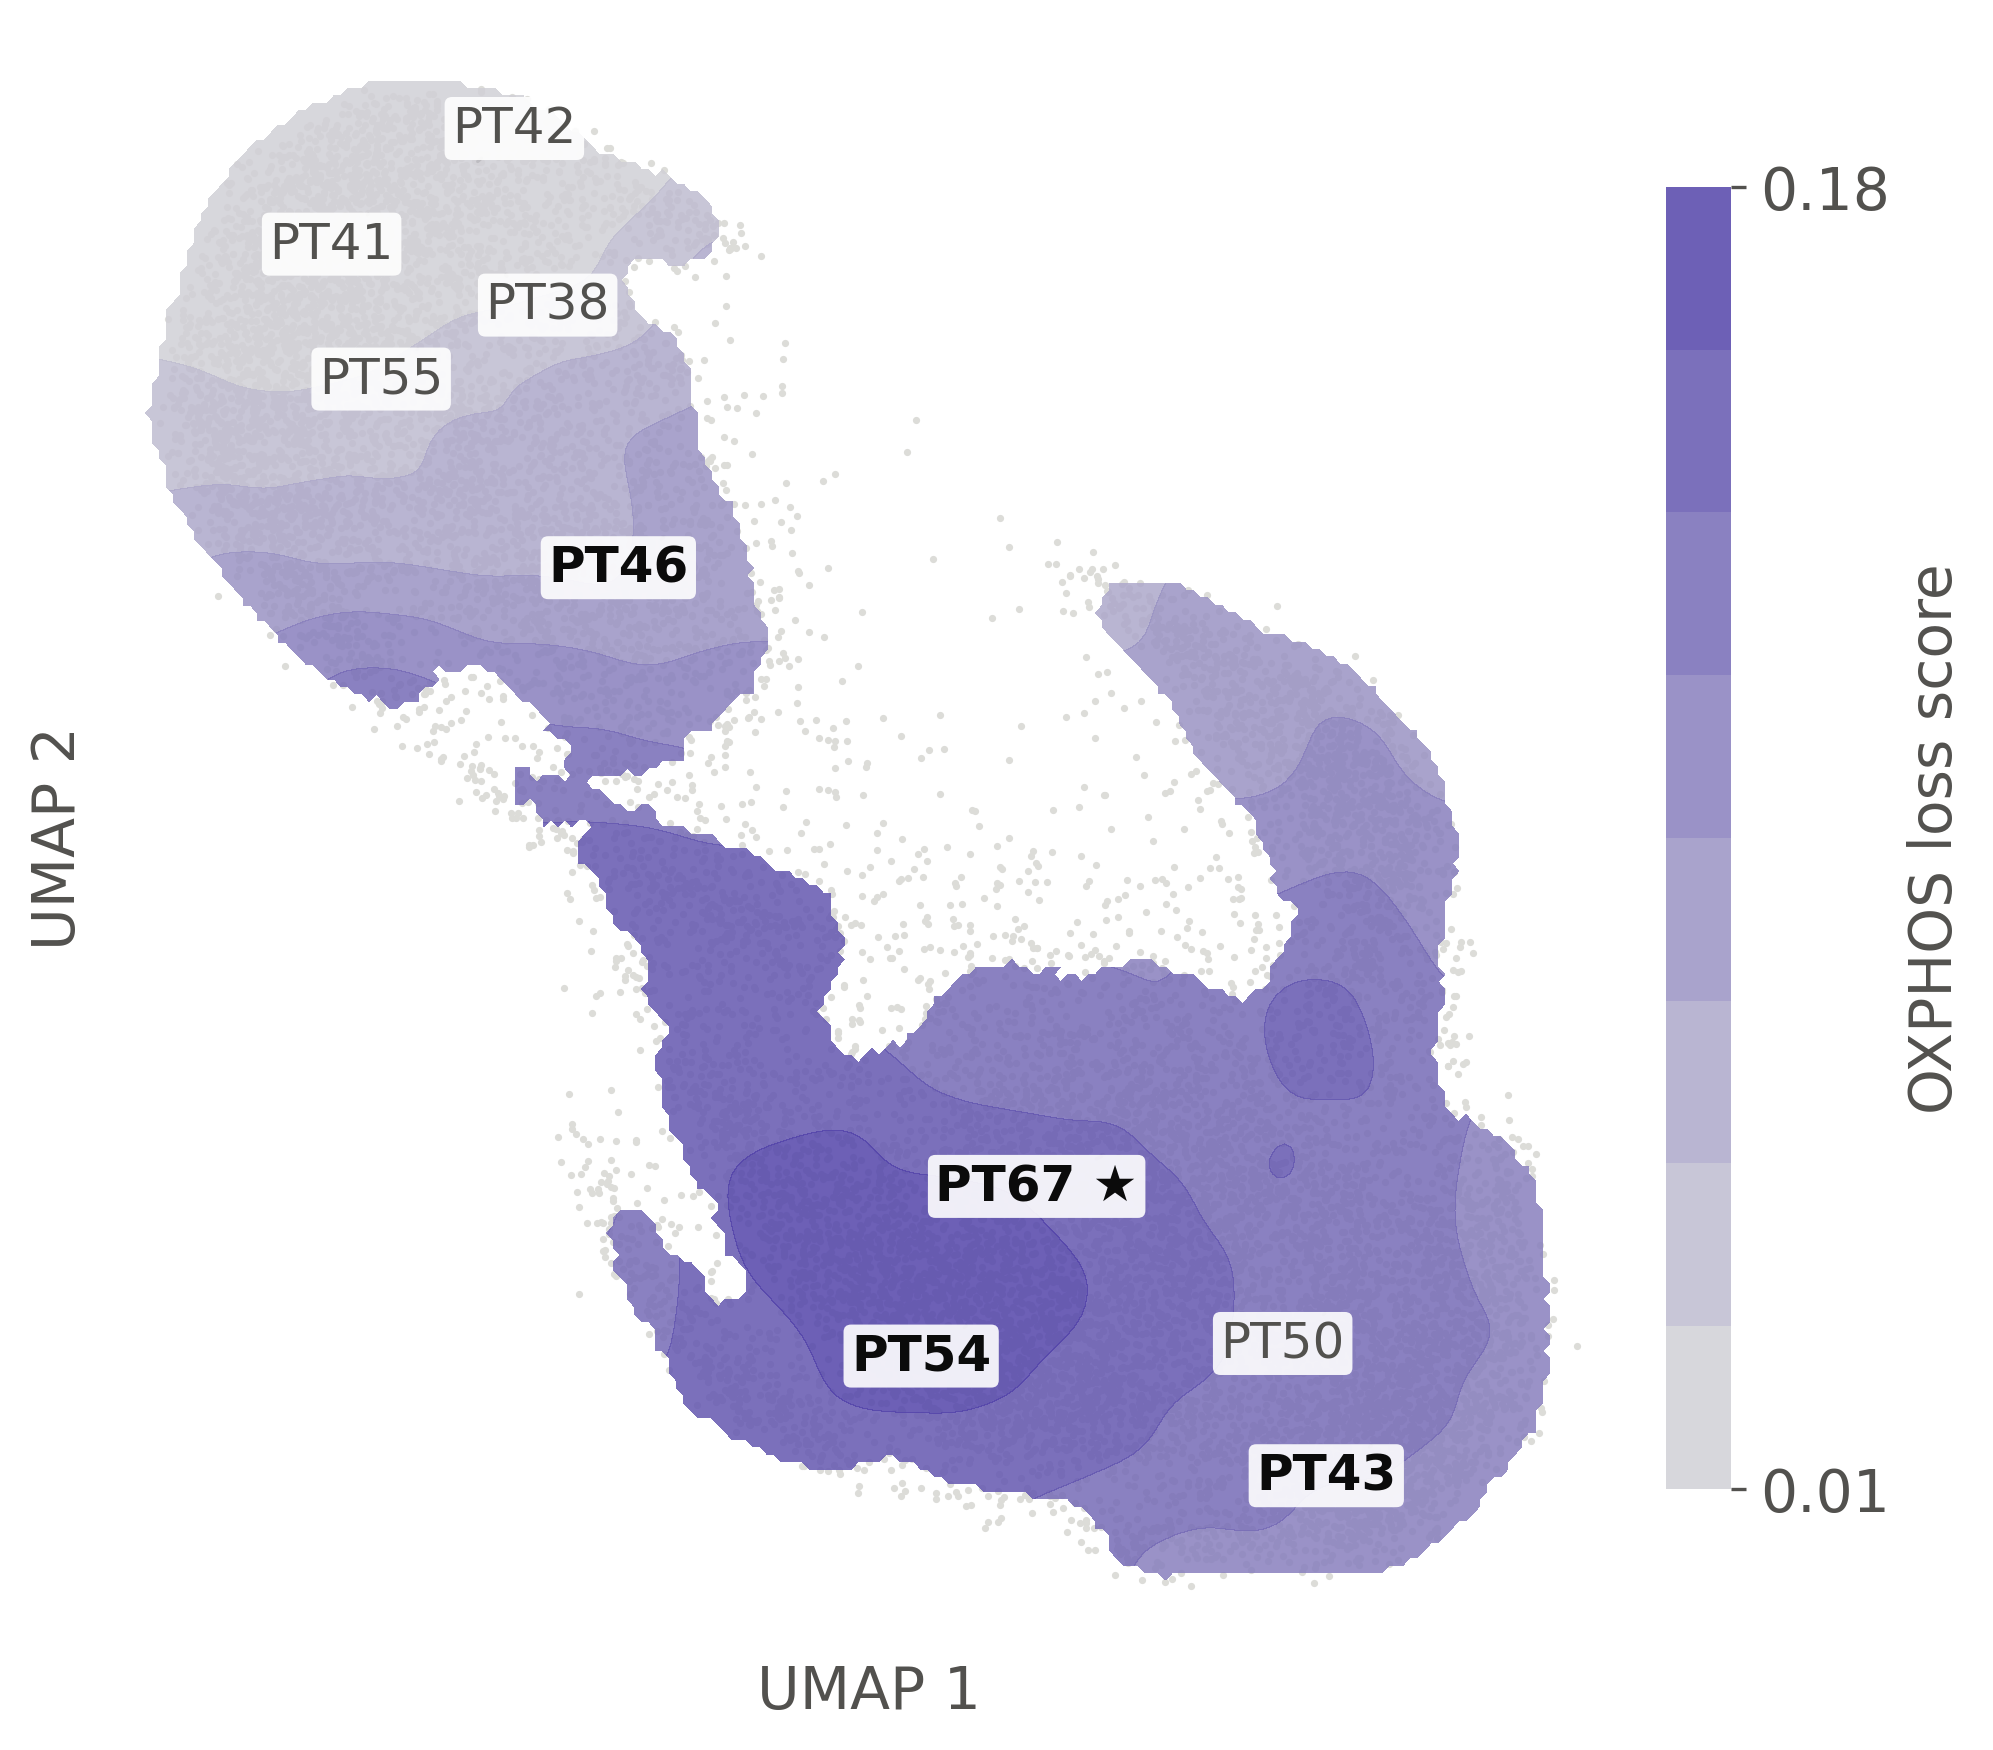

In [4]:
P.panel_umap_density(score, OUT, 'mono', 'fig6c_umap')
nb.show(OUT, 'fig6c_umap')

## D — donors clustered label-free on the ExPert latent vs expression (circular trees)

  wrote fig6d_trees.svg / .png


[e] trees: ExPert ARI 1.00 p 0.008 AUC 1.00 | expression ARI -0.01 p 0.524 AUC 0.84


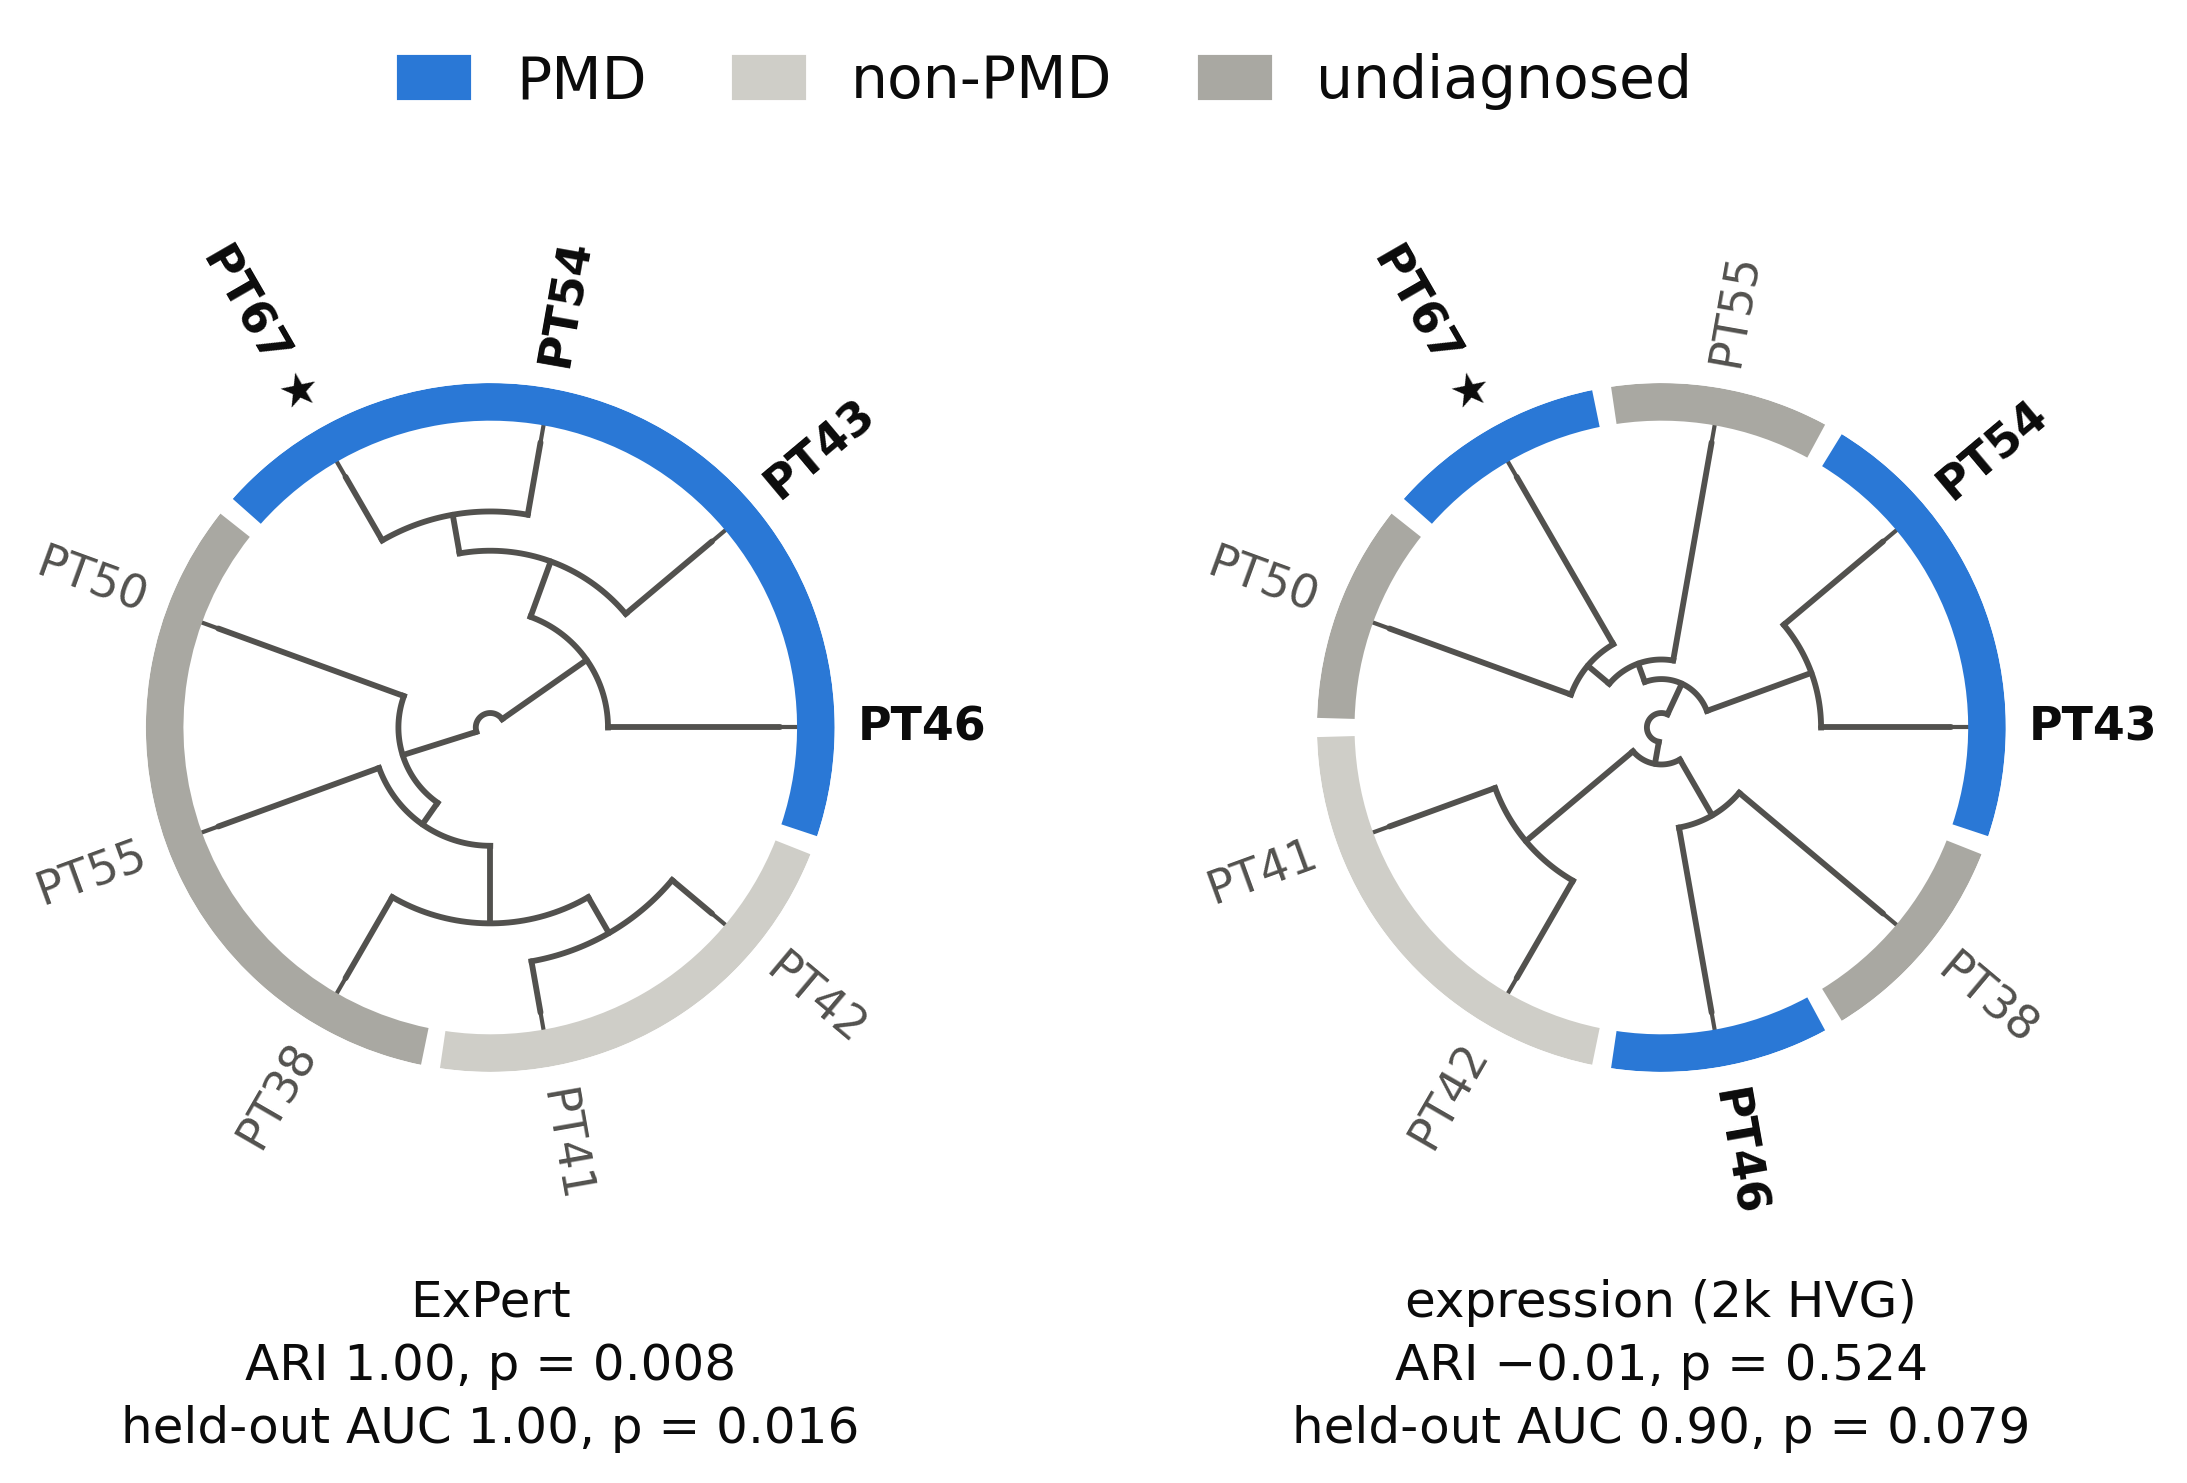

In [5]:
P.panel_trees(score, DATA / 'rna', OUT, a.space, name='fig6d_trees')
nb.show(OUT, 'fig6d_trees')

## E — per-donor predicted loss of PanelApp mitochondrial gene groups and lesion genes, monocytes

  wrote fig6e_pmd_genes_panelapp.svg / .png


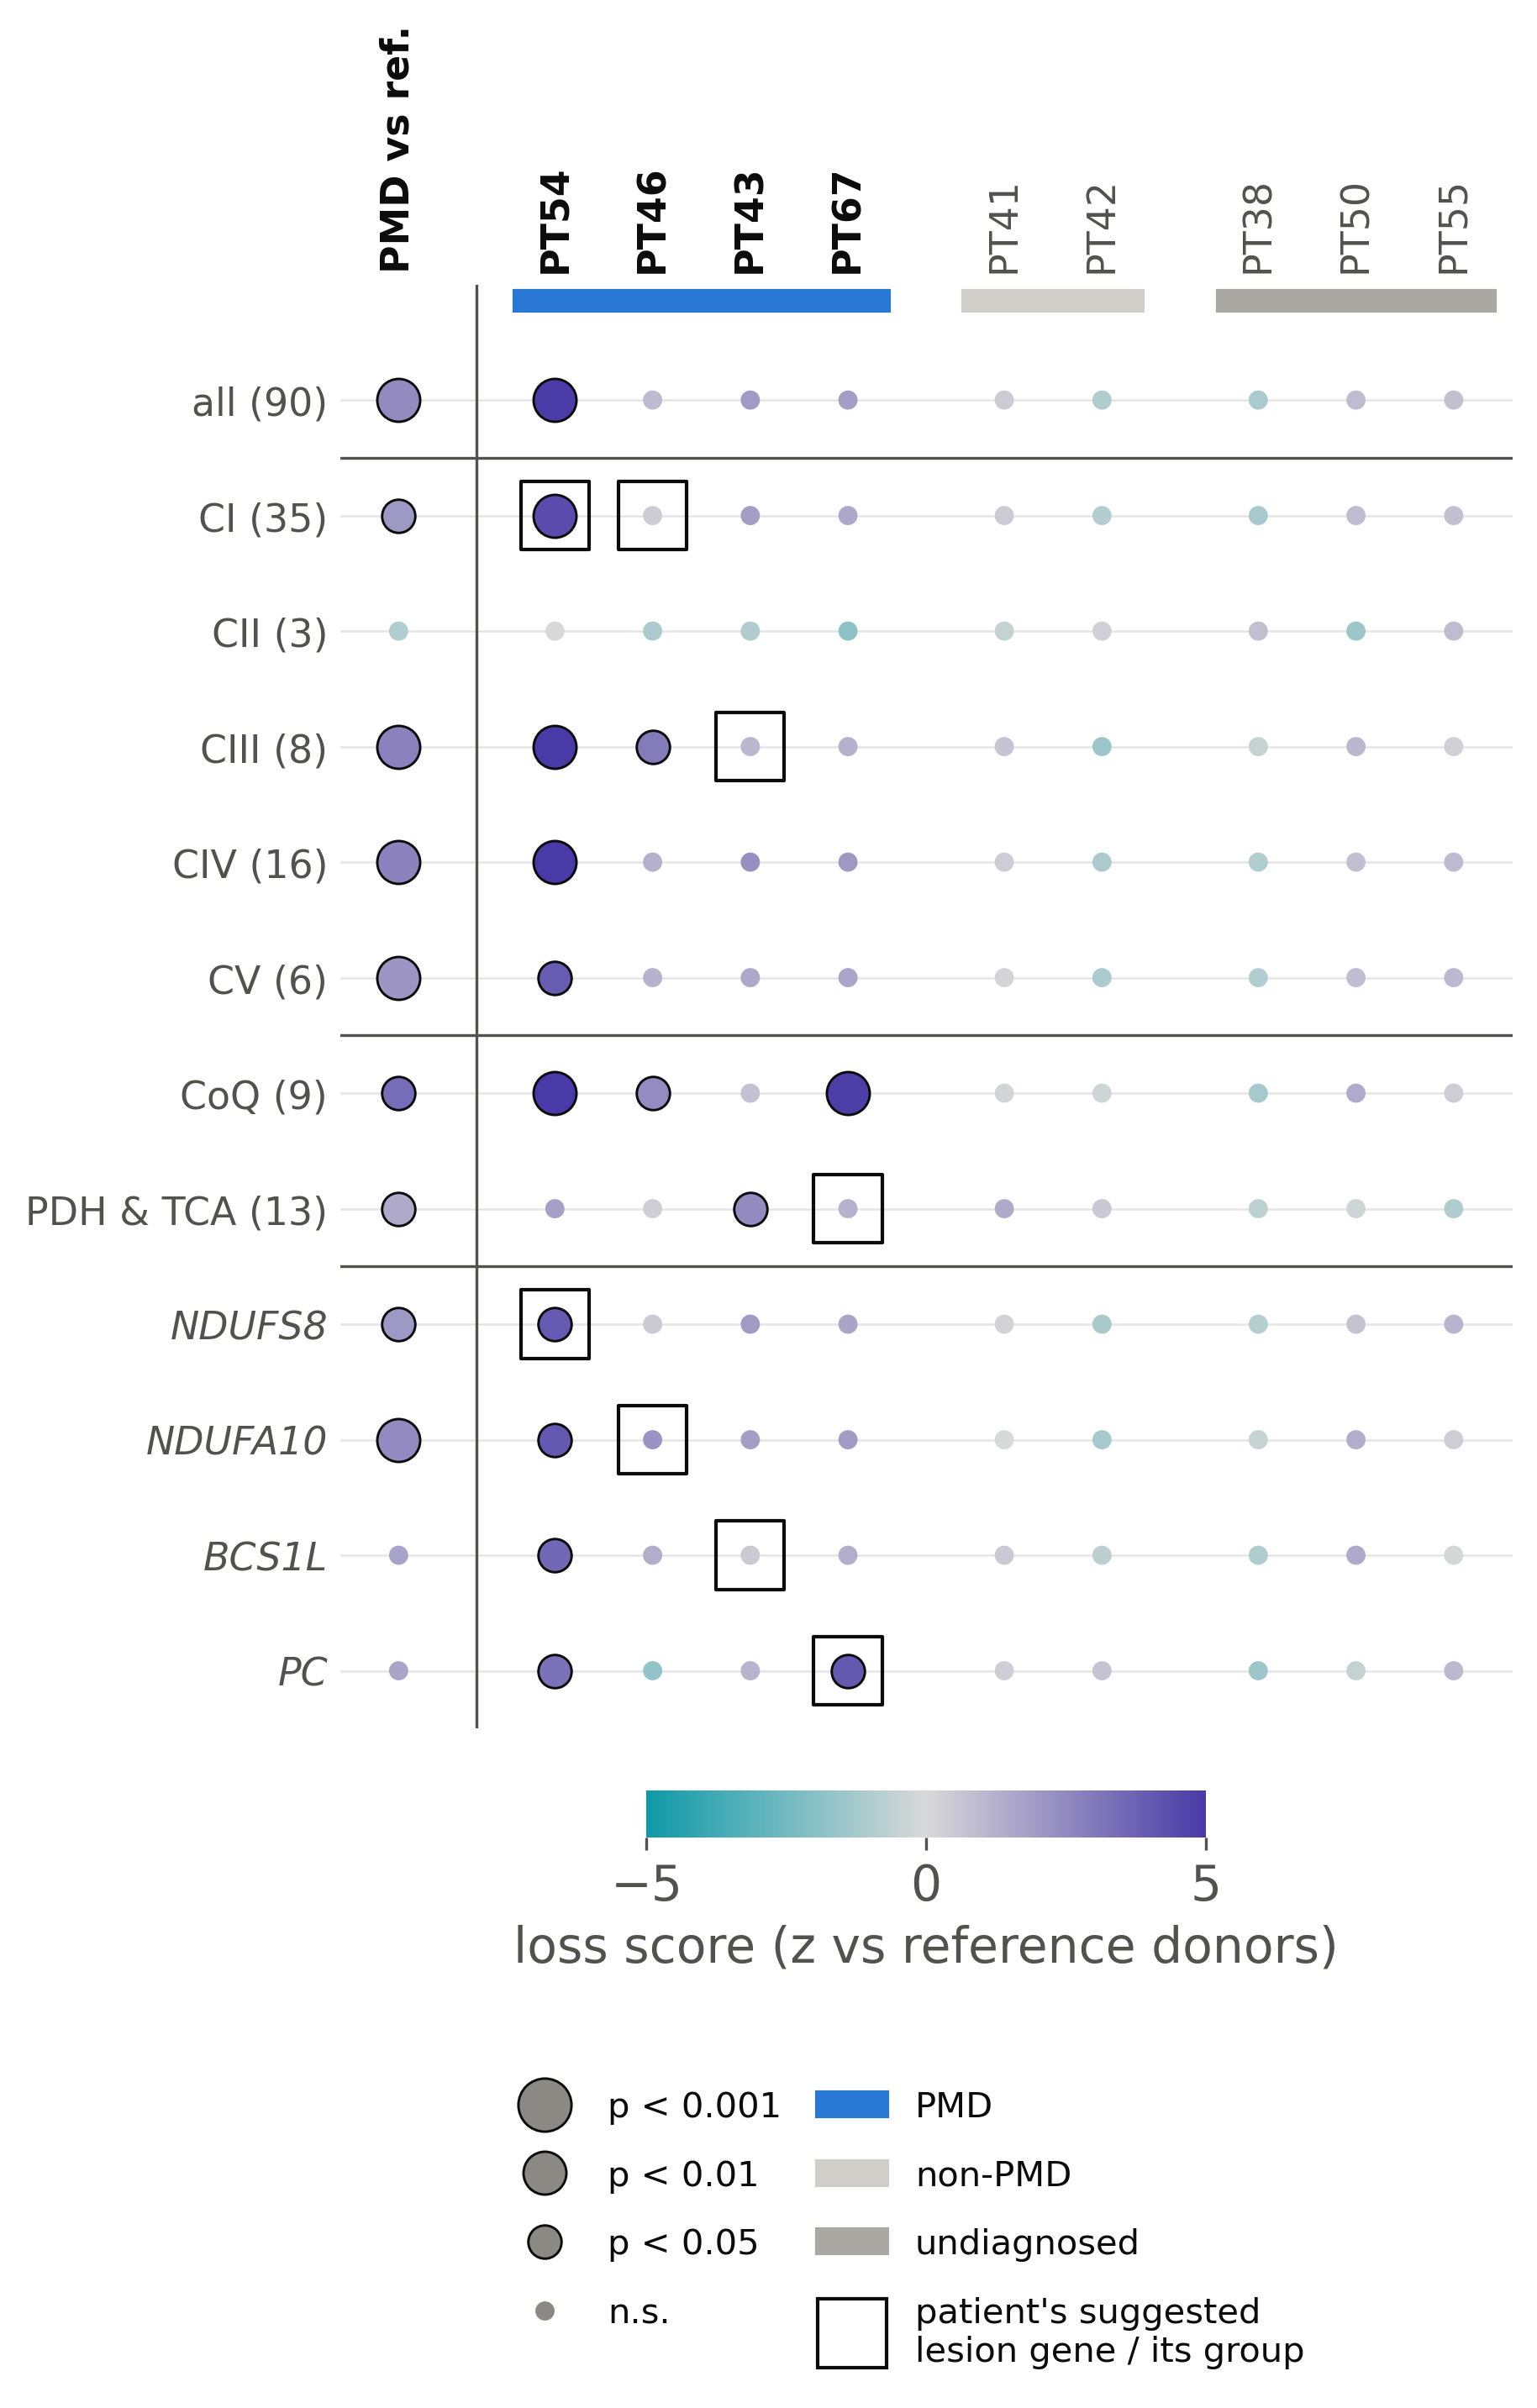

In [6]:
PE.main(PE.build_parser().parse_args([
    '--donor-mag', 'data/pmd_panel/donor_mag_trained.csv.gz', '--panel-dir', 'data/pmd_panel',
    '--out-dir', OUT_, '--src-dir', SRC_, '--vizstyle-root', STYLE,
    '--complexes', 'panel', '--name', 'fig6e_pmd_genes_panelapp']))
nb.show(OUT, 'fig6e_pmd_genes_panelapp')

## F — PMD vs reference donors per PBMC cell type (magnitude-aware loss score)

  wrote fig6f_pathways.svg / .png


[fig6f_pathways] p < .05: CI|Mono +2.2 p 0.024, CIII|Mono +2.7 p 0.008, CIV|Mono +2.8 p 0.008, CV|Mono +2.2 p 0.008, cap_translation|Mono +3.0 p 0.008, CoQ|CD4 T +1.8 p 0.036, CoQ|DC +2.6 p 0.040, CoQ|Mono +3.4 p 0.024, Fe-S & lipoate|Mono +2.4 p 0.008, PDH & TCA|Mono +1.5 p 0.040, carriers|unconv. T +3.2 p 0.029, import & dynamics|DC +1.5 p 0.040, import & dynamics|Mono +2.3 p 0.008, mt translation & RNA|CD4 T +1.8 p 0.018, mt translation & RNA|Mono +2.2 p 0.008, mtDNA maintenance|DC +1.9 p 0.040, mtDNA maintenance|Mono +2.7 p 0.008, Detoxification of Reac|DC +2.0 p 0.040, Detoxification of Reac|Mono +2.6 p 0.008, Macroautophagy|Mono +4.5 p 0.008, mTORC1-mediated Signal|Mono +3.7 p 0.008


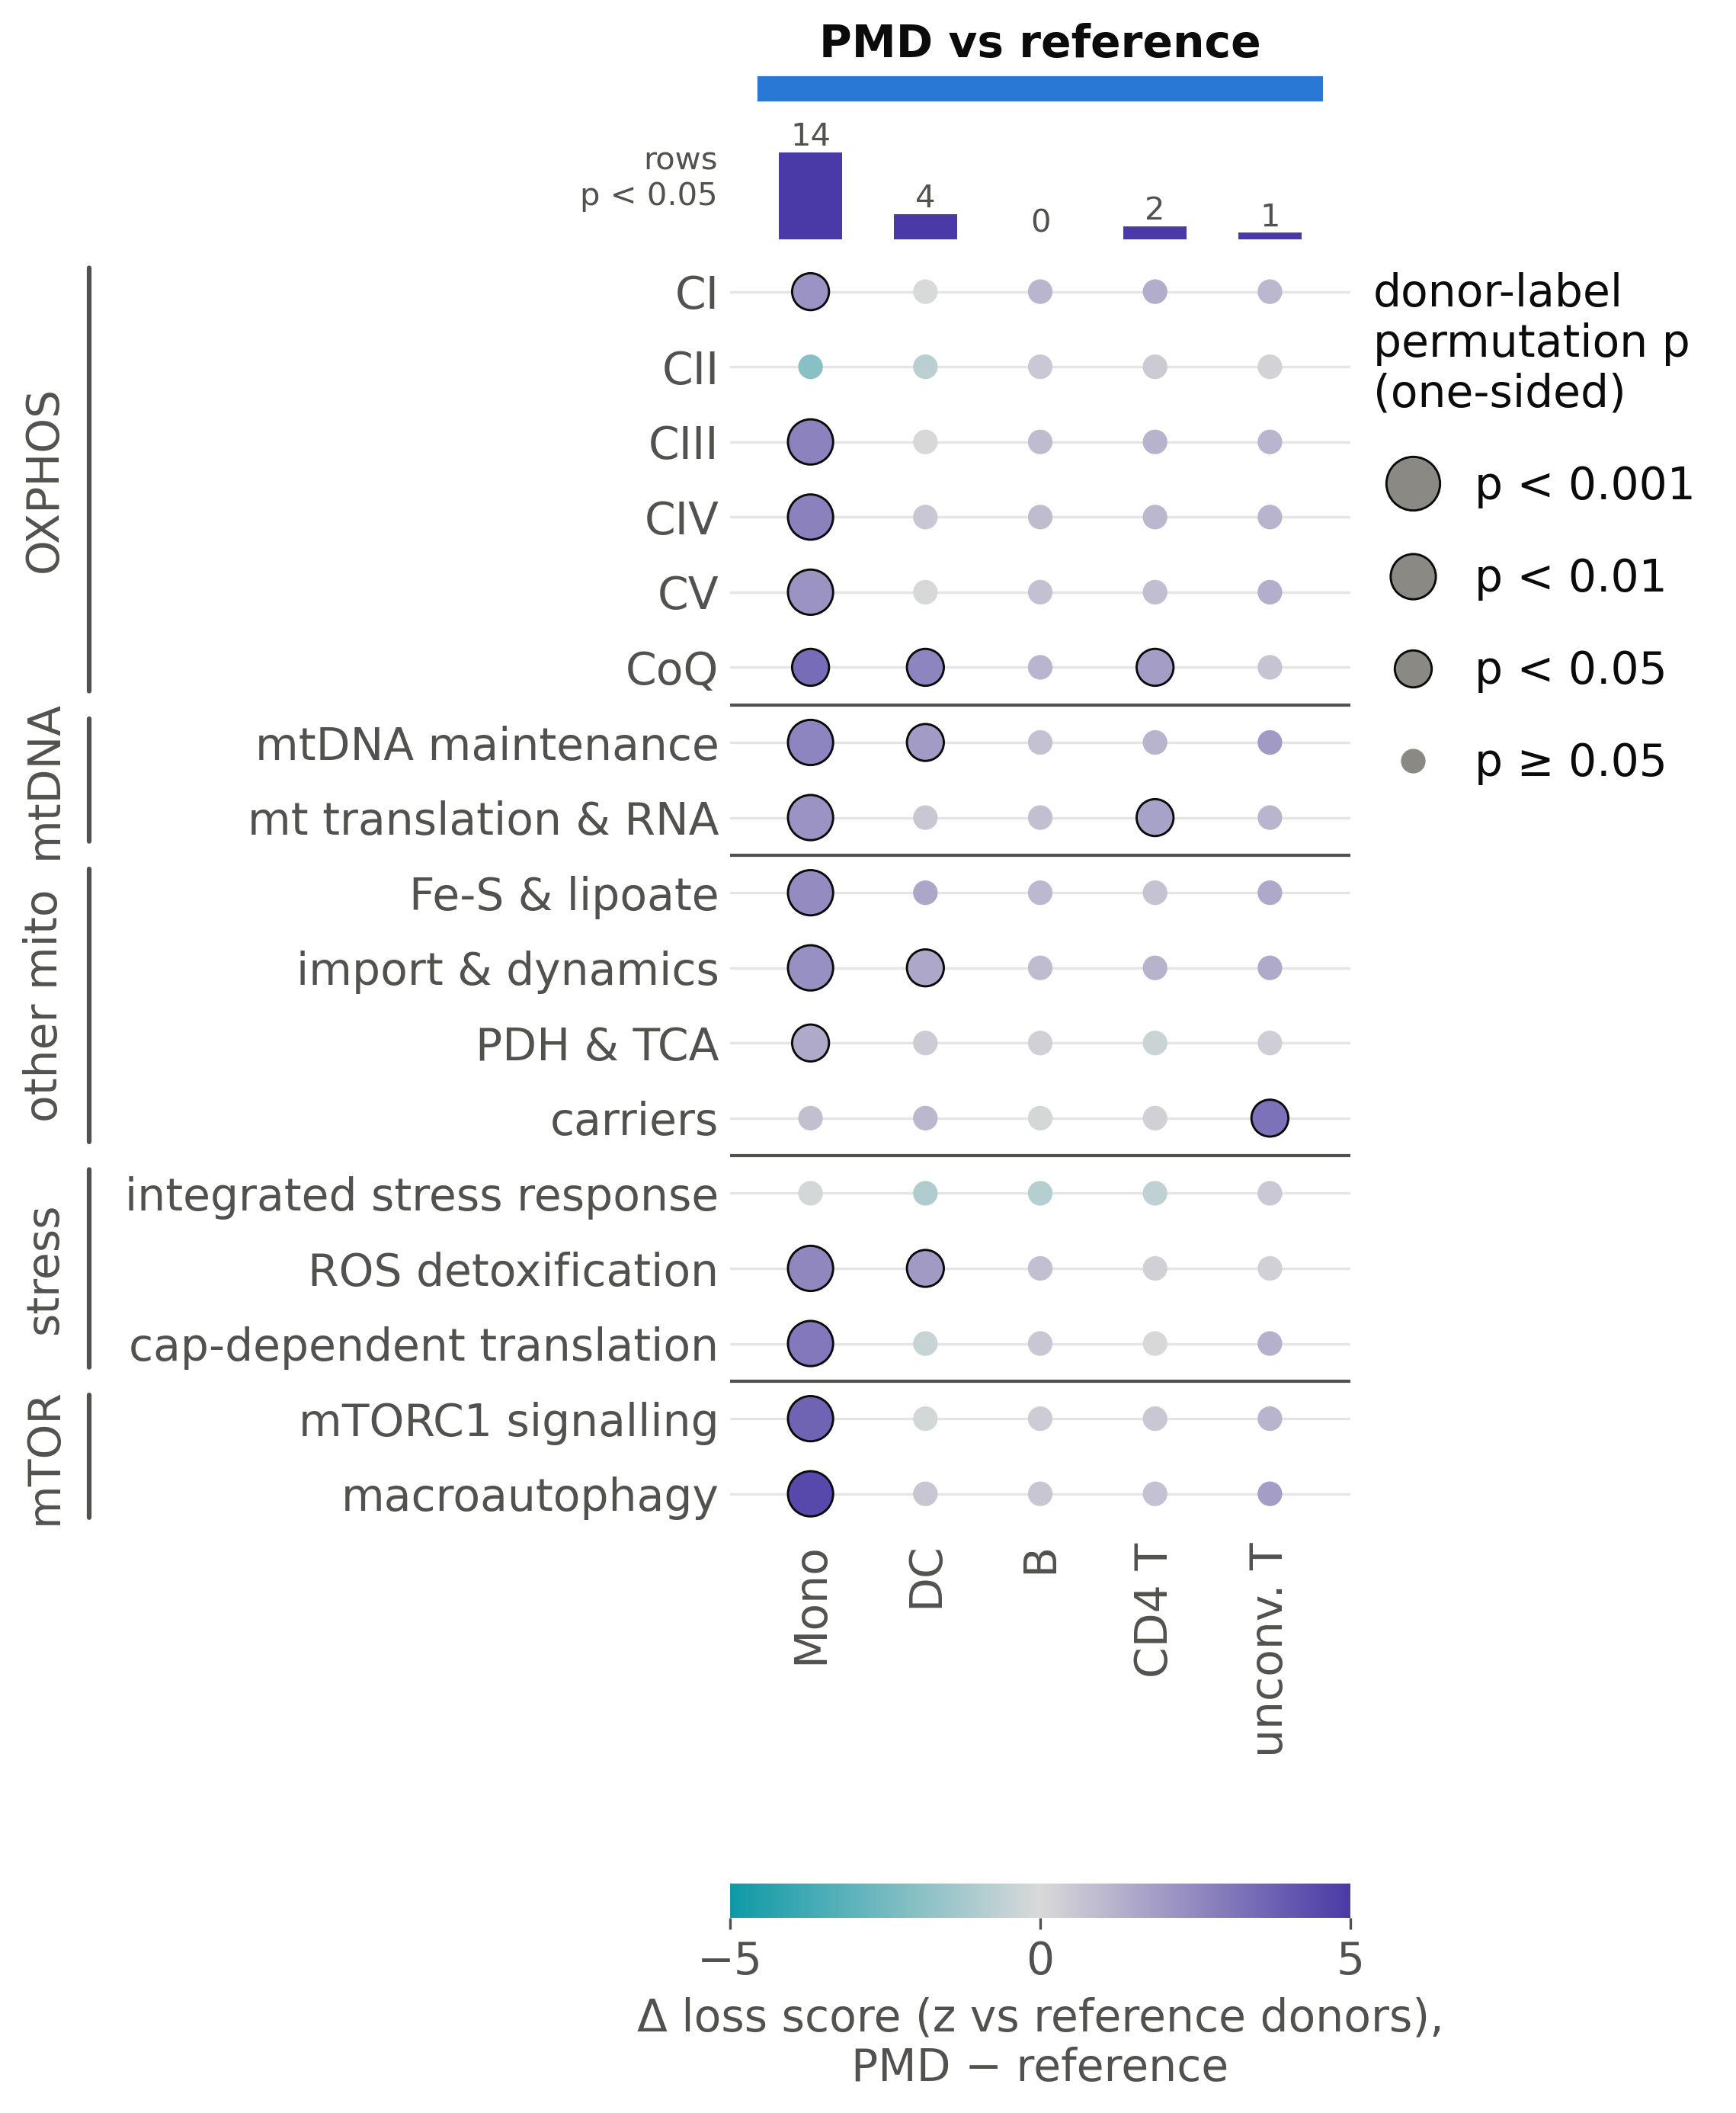

In [7]:
P.setup(STYLE)
P.panel_f(a, OUT, cts, SRC)
nb.show(OUT, 'fig6f_pathways')

## G — PCA of the sorted-cell bulk RNA-seq (right part of the panel)

  wrote fig6g_bulk_pca.svg / .png


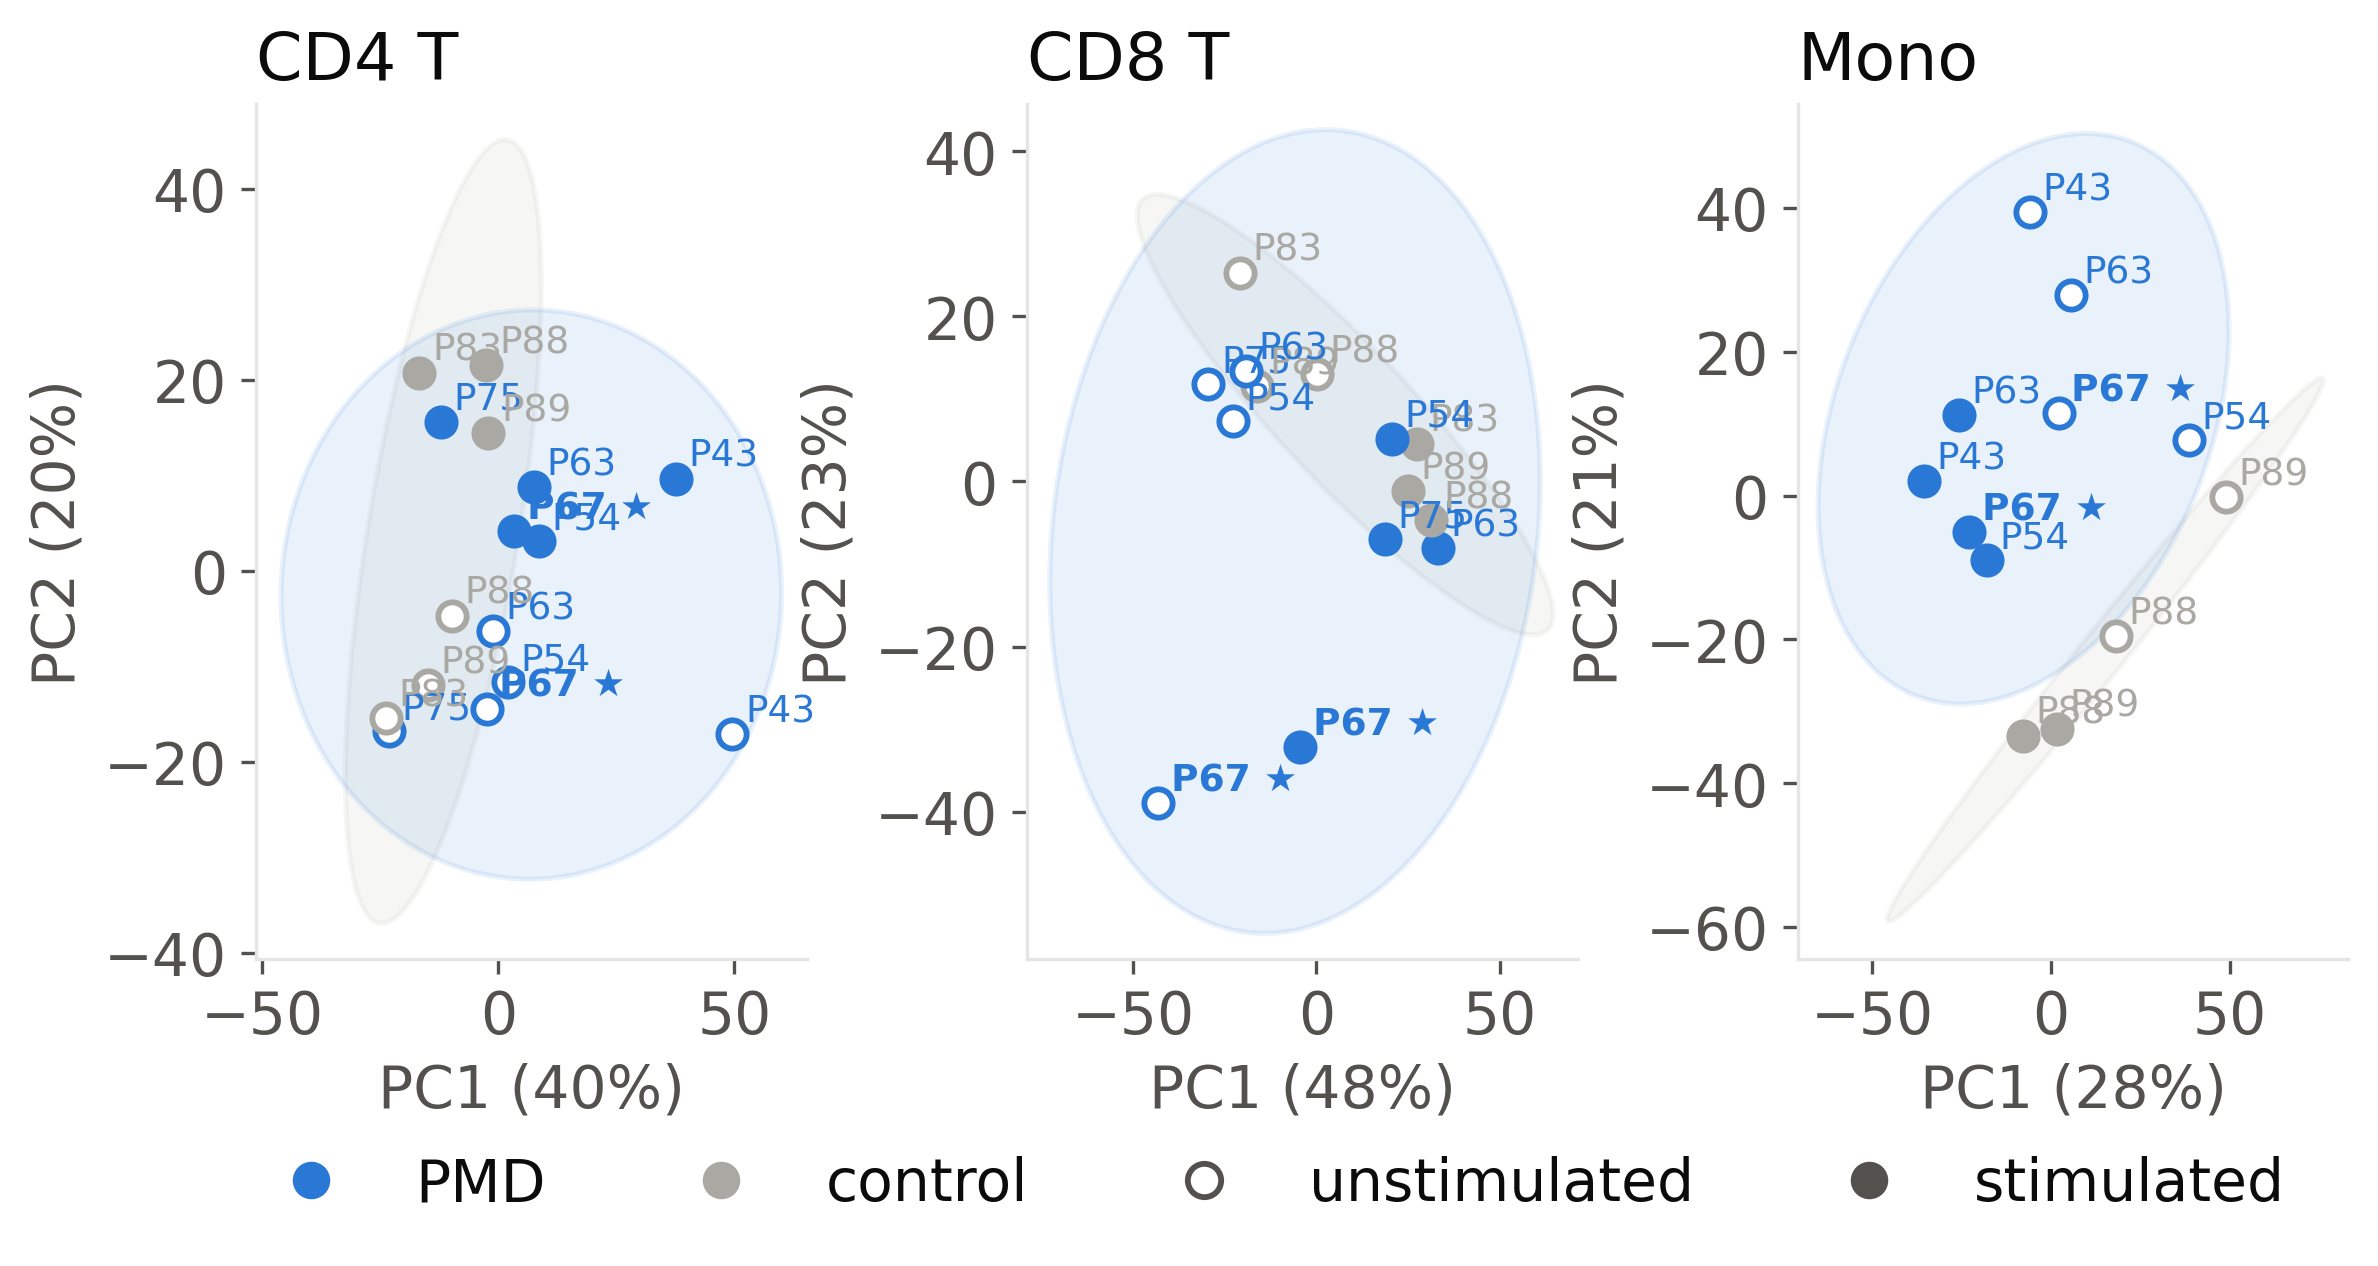

In [8]:
PB.main(PB.build_parser().parse_args([
    '--analysis-dir', 'data/mito_bulk/analysis_repro_collab', '--out-dir', OUT_, '--src-dir', SRC_,
    '--vizstyle-root', STYLE, '--panels', 'f2', '--pc-rule', 'other']))
nb.show(OUT, 'fig6g_bulk_pca')

## H — stimulation and disease principal components of the bulk PCA

  wrote fig6h_bulk_pc_scores.svg / .png


[fig6h_bulk_pc_scores] CD4: stim PC2 0.83, disease PC1 0.22; CD8: stim PC1 0.77, disease PC2 0.17; Mono: stim PC1 0.54, disease PC2 0.52


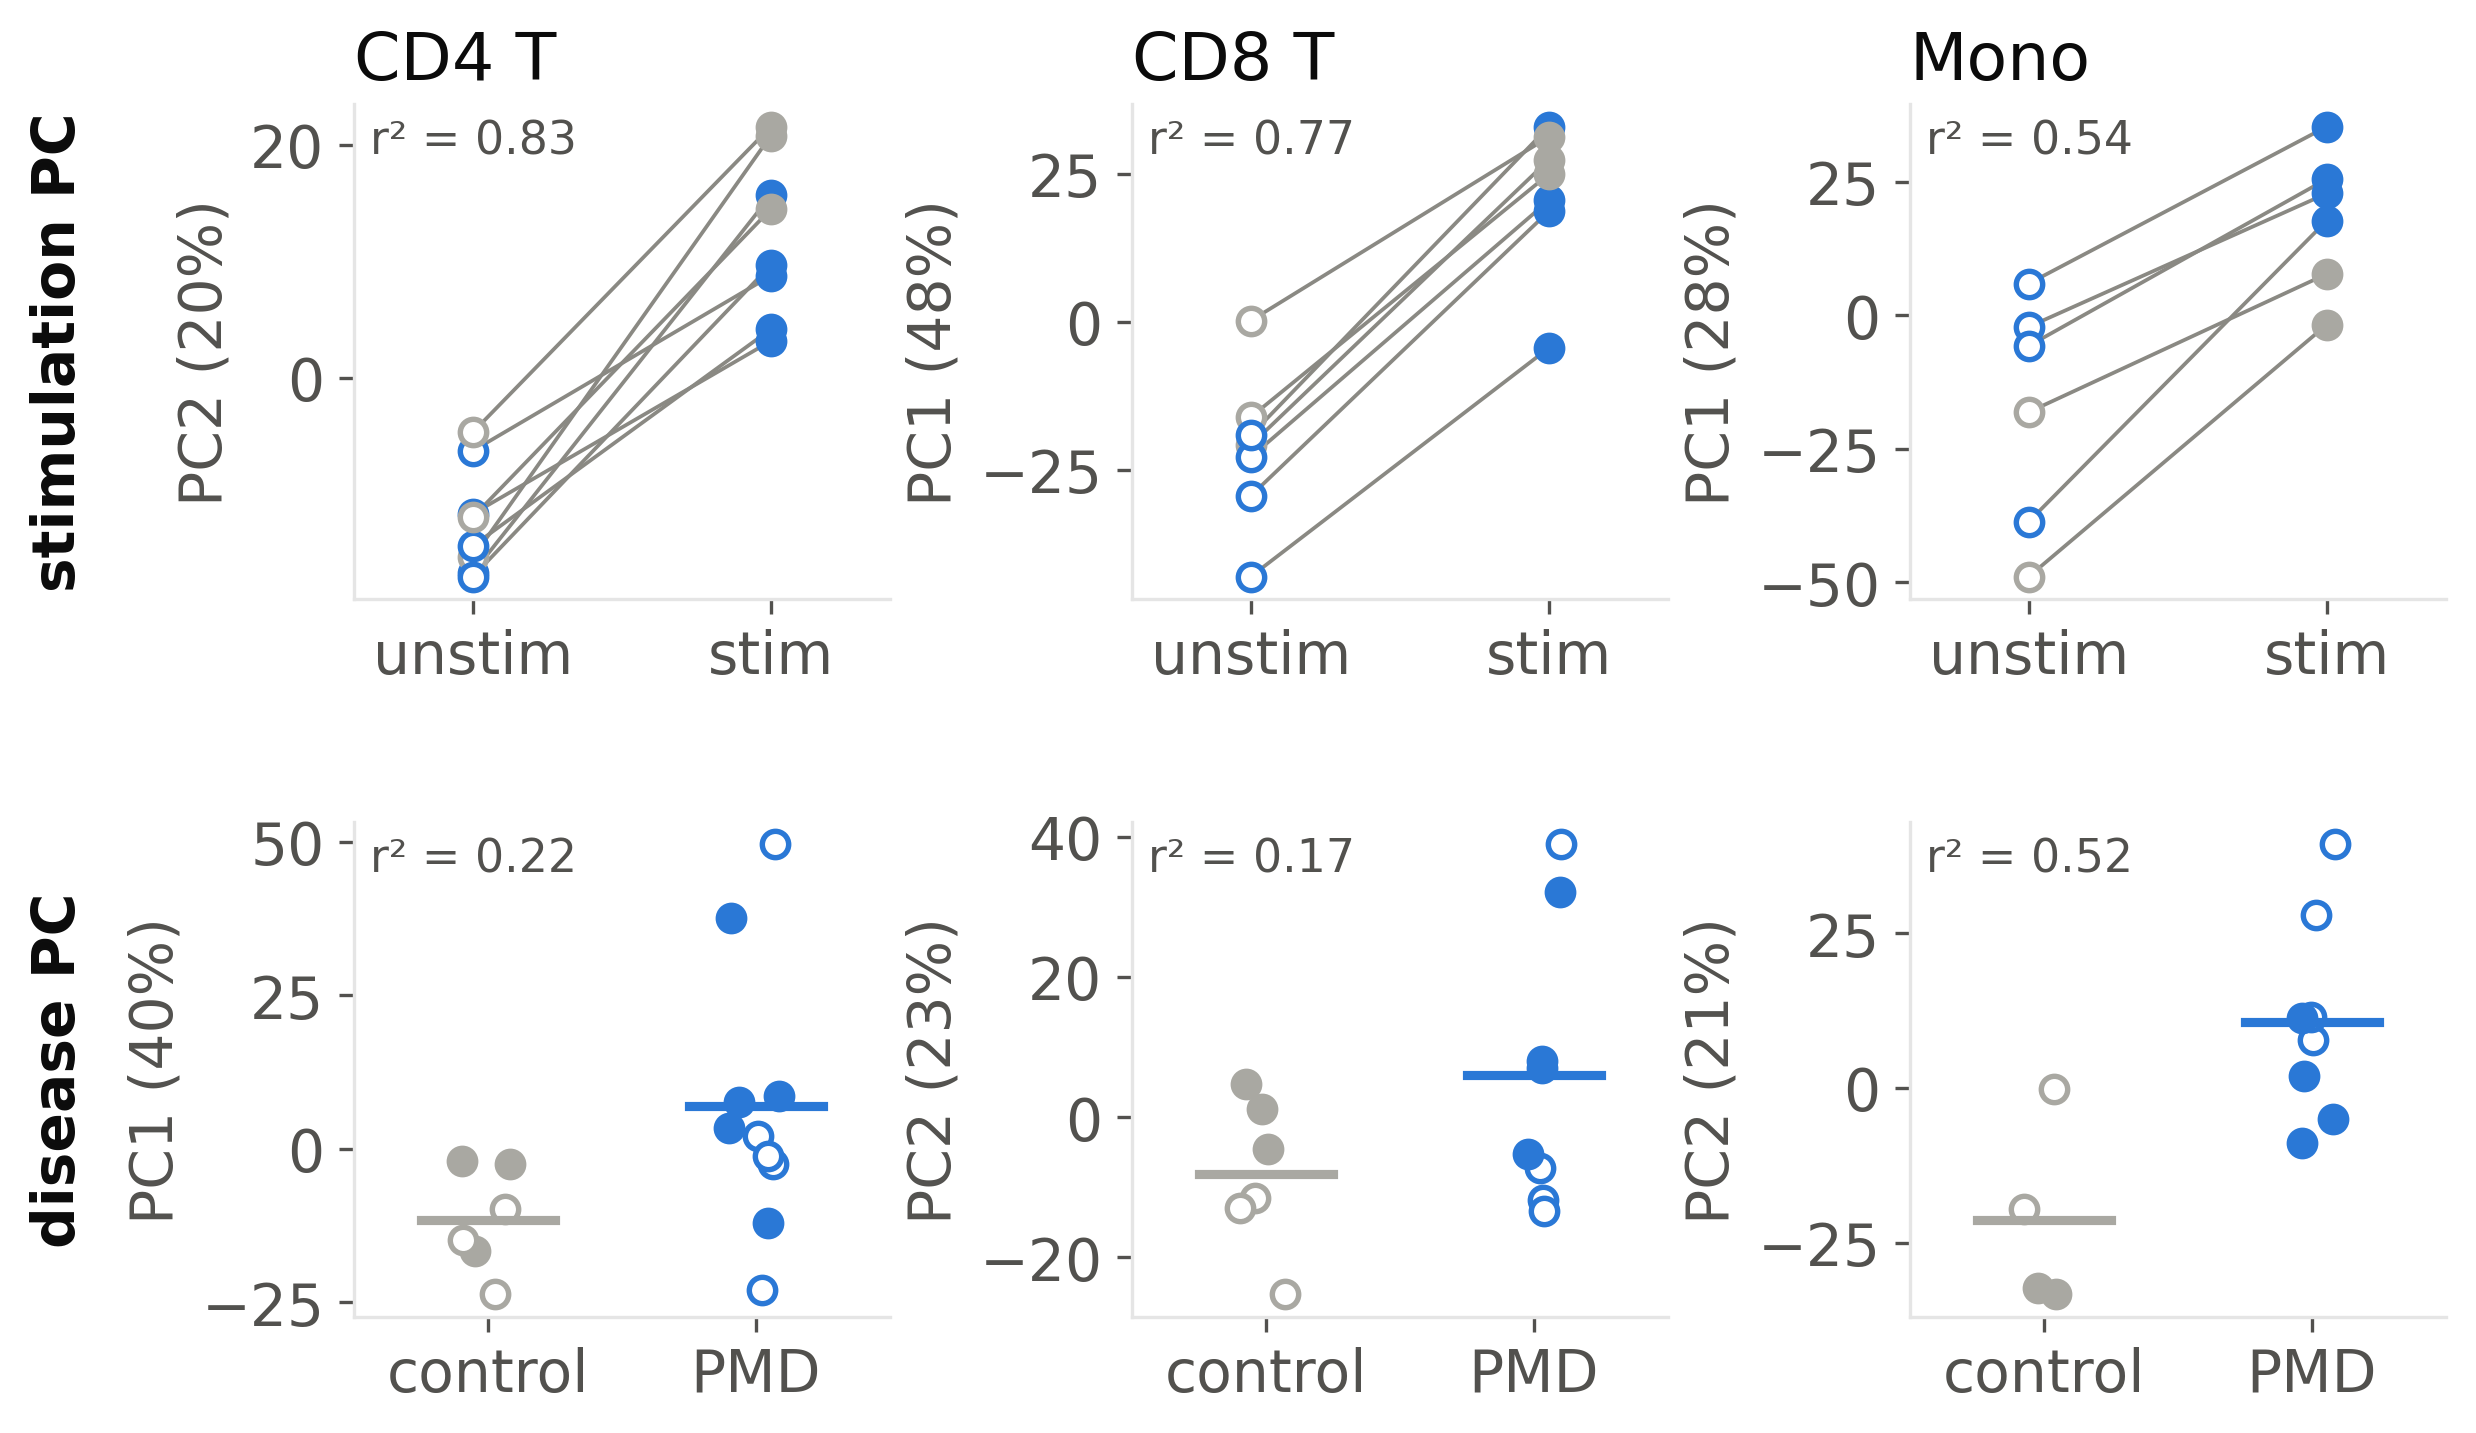

In [9]:
PB.main(PB.build_parser().parse_args([
    '--analysis-dir', 'data/mito_bulk/analysis_repro_collab', '--out-dir', OUT_, '--src-dir', SRC_,
    '--vizstyle-root', STYLE, '--panels', 'g2', '--pc-rule', 'other']))
nb.show(OUT, 'fig6h_bulk_pc_scores')

## I — flow cytometry: MitoTracker and CellROX change after stimulation, monocytes

  wrote fig6i_flow.svg / .png


    readout  n_control  n_pmd  mean_control  mean_pmd  p_student  p_welch  p_mannwhitney
MitoTracker          2      4       -4.5280   -6.9470     0.5954   0.5615         0.8000
    CellROX          2      4       36.0476  -28.5072     0.1238   0.2492         0.2667
excluded: {'Mono MT-TMRE': ['P75', 'P83'], 'Mono ROS': ['P75', 'P83']}


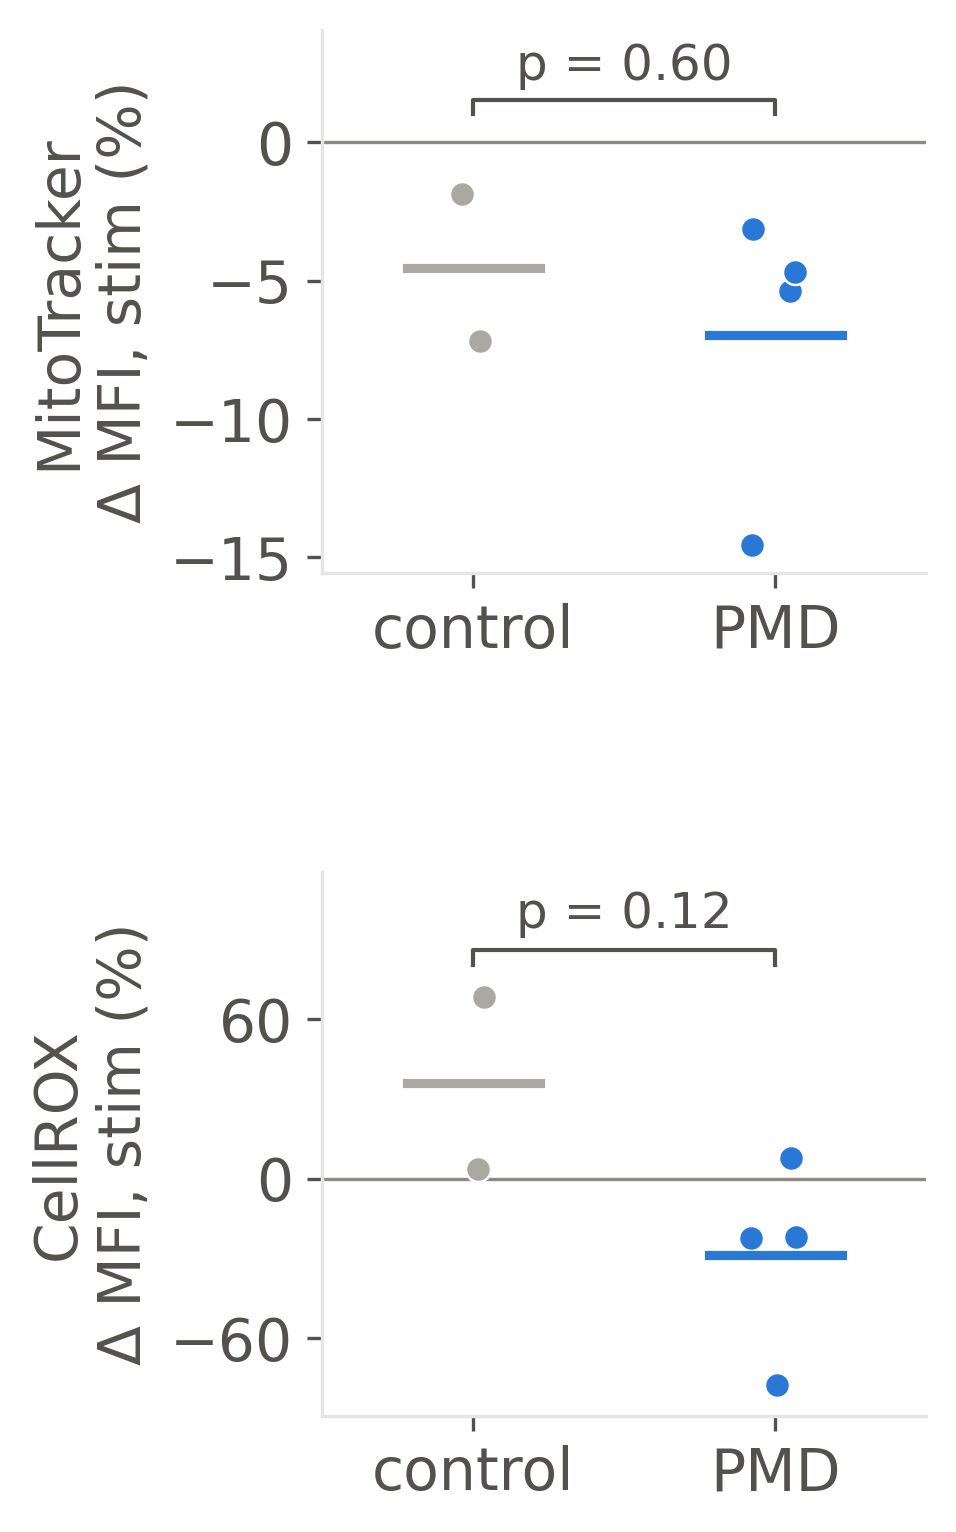

In [10]:
PF.main(PF.build_parser().parse_args([
    '--xlsx', 'data/flow/mito_flow_combined_raw.xlsx', '--out-dir', OUT_, '--src-dir', SRC_,
    '--vizstyle-root', STYLE]))
nb.show(OUT, 'fig6i_flow')